In [1]:
%load_ext watermark


In [2]:
import itertools as it

from IPython.display import display
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm

from pylib._osf_fetch import osf_fetch
from pylib.theory._calc_denovo_critical_potential_closed import (
    calc_denovo_critical_potential_closed,
)
from pylib.theory._calc_denovo_fixprob import calc_denovo_fixprob
from pylib.theory._calc_denovo_fixprob_demes2d import (
    calc_denovo_fixprob_demes2d,
)
from pylib.theory._calc_denovo_step_prob import calc_denovo_step_prob
from pylib.theory._resimulate_wellmixed import resimulate_wellmixed


In [3]:
%watermark -diwmuv -iv


Last updated: 2026-11-26T02:18:17.925459+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

numpy     : 2.1.2
seaborn   : 0.13.2
teeplot   : 1.2.0
matplotlib: 3.9.2
pandas    : 2.2.3
polars    : 1.9.0
scipy     : 1.14.1

Watermark: 2.4.3



In [4]:
teeplot_subdir = "theory-denovo-fixprob"
teeplot_subdir


'theory-denovo-fixprob'

# Predicting mutator fixation under *de novo* introduction

Companion to `theory-5050-npfix.ipynb`, whose notation this notebook shares.
Here the population is founded by nonmutators and each genome converts to mutator with probability $\mu = 10^{-6}$ per generation.
We predict the probability $P_\mathrm{fix}$ that mutators are fixed after 500,000 generations, as a function of population size $N$, adaptive potential $K$ (number of available beneficial mutations), and population structure.

## The model in brief

Mutators fix through a relay: some mutator lineage gets ahead of every nonmutator, and nonmutators then fail to catch up before they are gone.
Three closed-form laws describe the outcome.

**1. Small populations: one ticket per sweep.**
Beneficial mutations sweep one at a time.
Each mutator hitchhikes with probability $u_m / \delta$ before its load removes it (Raynes et al. 2018, eq. 1c), so the chance that a given sweep hands the population to mutators is

$$\rho = \frac{\mu\, u_m}{\delta\, u_n + \mu\, u_m} \approx 0.009, \qquad P_\mathrm{fix} \approx 1 - (1 - \rho)^K,$$

independent of $N$ (`calc_denovo_step_prob`).

**2. Large well-mixed populations: a critical adaptive potential.**
Sweeps overlap, and by the share law mutators' odds within each new fitness class multiply by $u_m / u_n$.
Mutators arising *de novo* are treated as present at their typical frequency $\bar{x} = (\mu / \delta)\,[1 - (1 - e^{-\delta T_\mathrm{non}}) / (\delta T_\mathrm{non})]$: their mutation-selection balance frequency, discounted for being purged by each nonmutator sweep (`calc_denovo_mutator_frequency`).
From there, mutators fix once nonmutators' share of the class below the peak is too small for them to catch up within a sweep time $T$:

$$K^* = 1 + \frac{\ln[N u_n T / (\bar{x} \ln 2)]}{\ln(u_m / u_n)}.$$

**3. Large structured populations: a race across space.**
A mutator lineage that gets ahead adapts faster than its surroundings but spreads no faster.
Mutators fix only if their domains, founded at rate $J = n\, \bar{x}\, u_m$ per deme per generation and spreading at speed $v$, cover all $N / n$ demes before nonmutators climb $K$ steps at one sweep time $T_\mathrm{non}$ each:

$$K^* = \frac{1}{T_\mathrm{non}} \left\{\frac{3 \ln[N / (n \ln 2)]}{\pi J v^2}\right\}^{1/3}, \qquad \text{peak mutator prevalence} = 1 - e^{-\pi J v^2 (K\, T_\mathrm{non})^3 / 3}.$$

In both large-population laws $K^*$ depends only logarithmically on $N$ and $\mu$; structure raises it severalfold (`calc_denovo_critical_potential_closed`, `calc_denovo_peak_prevalence_closed`).

Curves below labeled "theory" come from numerical models that interpolate between these regimes: `calc_denovo_fixprob` (well-mixed) treats mutator lineages as a branching process riding the nonmutators' adaptation, and `calc_denovo_fixprob_demes2d` integrates the race across space.
Drift fixation of loaded mutators is added per Kimura; it matters only for $N = 256$.


## Theory


In [5]:
rho = calc_denovo_step_prob()
rho


0.009059137919010585

In [6]:
data_Ns = [256, 2304, 20736, 186624, 1679616, 15116544]
theory_Ks = [1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 20, 24, 32, 40]
records = []
for N, K in tqdm([*it.product(data_Ns, theory_Ks)]):
    if N == 256 and K > 12:
        continue  # excluded from manuscript; adaptive potential not reached
    records.append(
        {
            "population size": N,
            "available beneficial mutations": K,
            "fixation probability": calc_denovo_fixprob(N, K),
            "treatment": "theory (well-mixed)",
        },
    )
df_theory = pd.DataFrame(records)
df_theory


100%|██████████| 84/84 [02:14<00:00,  1.61s/it]


,population size,available beneficial mutations,fixation probability,treatment
0,256,1,0.024565,theory (well-mixed)
1,256,2,0.032678,theory (well-mixed)
2,256,3,0.040723,theory (well-mixed)
3,256,4,0.048701,theory (well-mixed)
4,256,6,0.064458,theory (well-mixed)
...,...,...,...,...
73,15116544,16,0.997028,theory (well-mixed)
74,15116544,20,0.999660,theory (well-mixed)
75,15116544,24,0.999961,theory (well-mixed)
76,15116544,32,0.999999,theory (well-mixed)


## Prep Data


In [7]:
def load_fixprobs(url: str) -> pl.DataFrame:
    """Tabulate final mutator fraction per replicate population, from
    tile-level trait counts."""
    df = pl.from_pandas(pd.read_parquet(osf_fetch(url)))
    df = (
        df.with_columns(
            pl.when(pl.col("nRowSubgrid") == 0)
            .then(pl.col("nRow"))
            .otherwise(pl.col("nRowSubgrid"))
            .cast(pl.UInt64)
            .alias("nRowSubgrid"),
            pl.when(pl.col("nColSubgrid") == 0)
            .then(pl.col("nCol"))
            .otherwise(pl.col("nColSubgrid"))
            .cast(pl.UInt64)
            .alias("nColSubgrid"),
        )
        .with_columns(
            (pl.col("row").cast(pl.UInt64) // pl.col("nRowSubgrid")).alias(
                "rowGroup"
            ),
            (pl.col("col").cast(pl.UInt64) // pl.col("nColSubgrid")).alias(
                "colGroup"
            ),
            (
                pl.col("nColSubgrid")
                * pl.col("nRowSubgrid")
                * pl.col("tilePopSize").cast(pl.UInt64)
            ).alias("population size"),
        )
        .filter(pl.col("trait value") == 1)
    )
    return (
        df.group_by(
            ["replicate", "nBen", "population size", "rowGroup", "colGroup"],
        )
        .agg(
            (pl.col("trait count").sum() / pl.col("tilePopSize").sum()).alias(
                "mutator fraction"
            ),
        )
        .select(
            pl.col("nBen")
            .cast(pl.Int64)
            .alias("available beneficial mutations"),
            pl.col("population size"),
            pl.col("mutator fraction"),
        )
    )


dfs = [
    load_fixprobs(url).with_columns(pl.lit(treatment).alias("treatment"))
    for treatment, url in tqdm(
        [
            ("well-mixed (GPU)", "https://osf.io/edwbu/download"),
            ("2D, 256/deme (GPU)", "https://osf.io/ag4ur/download"),
        ],
    )
]
# 2D, 256/deme (WSE) is published pre-tabulated
dfs.append(
    pl.from_pandas(pd.read_parquet(osf_fetch("https://osf.io/eacvu/download")))
    .filter(pl.col("trait value") == 1)
    .select(
        pl.col("available beneficial mutations").cast(pl.Int64),
        pl.col("population size").cast(pl.UInt64),
        pl.col("fixation probability").alias("mutator fraction"),
        pl.lit("2D, 256/deme (WSE)").alias("treatment"),
    ),
)
df_reps = pl.concat(dfs)
df_reps


  0%|          | 0/2 [00:00<?, ?it/s]

downloading https://osf.io/edwbu/download -> /tmp/edwbu
size: 59971615 bytes


 50%|█████     | 1/2 [00:04<00:04,  4.84s/it]

downloading https://osf.io/ag4ur/download -> /tmp/ag4ur
size: 85511876 bytes


100%|██████████| 2/2 [00:11<00:00,  5.70s/it]


downloading https://osf.io/eacvu/download -> /tmp/eacvu
size: 42358218 bytes


available beneficial mutations,population size,mutator fraction,treatment
i64,u64,f64,str
16,256,1.0,"""well-mixed (GPU)"""
16,256,0.0,"""well-mixed (GPU)"""
12,256,0.0,"""well-mixed (GPU)"""
40,256,0.0,"""well-mixed (GPU)"""
8,256,0.0,"""well-mixed (GPU)"""
…,…,…,…
16,190848000,0.000102,"""2D, 256/deme (WSE)"""
12,190848000,0.000091,"""2D, 256/deme (WSE)"""
16,190848000,0.000092,"""2D, 256/deme (WSE)"""


In [8]:
def add_wilson_ci(df: pd.DataFrame) -> pd.DataFrame:
    cis = [
        scipy_stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
        for k, n in zip(df["num mutator"], df["num replicates"])
    ]
    df["fixation probability"] = df["num mutator"] / df["num replicates"]
    df["ci lo"] = [ci.low for ci in cis]
    df["ci hi"] = [ci.high for ci in cis]
    return df


df_data = add_wilson_ci(
    df_reps.group_by(
        ["treatment", "population size", "available beneficial mutations"],
    )
    .agg(
        pl.len().alias("num replicates"),
        (pl.col("mutator fraction") == 1.0).sum().alias("num mutator"),
    )
    .sort(["treatment", "population size", "available beneficial mutations"])
    .to_pandas(),
)
with pd.option_context("display.max_rows", None):
    display(df_data)


,treatment,population size,available beneficial mutations,num replicates,num mutator,fixation probability,ci lo,ci hi
0,"2D, 256/deme (GPU)",256,1,59049,1584,0.026825,0.025552,0.028159
1,"2D, 256/deme (GPU)",256,4,59049,3195,0.054108,0.052312,0.055961
2,"2D, 256/deme (GPU)",256,8,59049,5228,0.088537,0.086272,0.090855
3,"2D, 256/deme (GPU)",256,10,59049,6217,0.105285,0.102836,0.107787
4,"2D, 256/deme (GPU)",256,12,59049,7161,0.121272,0.118664,0.123930
5,"2D, 256/deme (GPU)",256,14,59049,8064,0.136565,0.133819,0.139358
6,"2D, 256/deme (GPU)",256,16,59049,8976,0.152009,0.149136,0.154928
7,"2D, 256/deme (GPU)",256,20,59049,10534,0.178394,0.175327,0.181503
8,"2D, 256/deme (GPU)",256,24,59049,11525,0.195177,0.192000,0.198393
9,"2D, 256/deme (GPU)",256,32,59049,12091,0.204762,0.201527,0.208036


## Resimulation of Well-mixed Treatment

Published well-mixed data reach 15 million agents, with 9 replicates at the largest sizes.
To test theory more closely there and beyond, we resimulate the well-mixed model by tracking counts of each (mutator, beneficial, deleterious) genotype class rather than individual agents.


In [9]:
resim_Ns = [int(round(10**x)) for x in np.arange(5.5, 9.51, 0.5)]
resim_Ks = [2, 4, 6, 8, 10, 12, 16, 20]
records = []
for N, K in tqdm([*it.product(resim_Ns, resim_Ks)]):
    won = resimulate_wellmixed(
        N, K, n_rep=200, x0=0.0, mu=1e-6, seed=N % 1000 + K
    )
    records.append(
        {
            "treatment": "well-mixed (resimulated)",
            "population size": N,
            "available beneficial mutations": K,
            "num replicates": len(won),
            "num mutator": int(won.sum()),
        },
    )
df_resim = add_wilson_ci(pd.DataFrame(records))
df_resim


100%|██████████| 72/72 [01:38<00:00,  1.37s/it]


,treatment,population size,available beneficial mutations,num replicates,num mutator,fixation probability,ci lo,ci hi
0,well-mixed (resimulated),316228,2,200,0,0.000,0.000000,0.018845
1,well-mixed (resimulated),316228,4,200,6,0.030,0.013820,0.063894
2,well-mixed (resimulated),316228,6,200,14,0.070,0.042152,0.114055
3,well-mixed (resimulated),316228,8,200,20,0.100,0.065670,0.149406
4,well-mixed (resimulated),316228,10,200,27,0.135,0.094466,0.189291
...,...,...,...,...,...,...,...,...
67,well-mixed (resimulated),3162277660,8,200,199,0.995,0.972226,0.999117
68,well-mixed (resimulated),3162277660,10,200,200,1.000,0.981155,1.000000
69,well-mixed (resimulated),3162277660,12,200,200,1.000,0.981155,1.000000
70,well-mixed (resimulated),3162277660,16,200,200,1.000,0.981155,1.000000


In [10]:
records = []
for N, K in tqdm([*it.product(resim_Ns, [*range(1, 17), 20])]):
    records.append(
        {
            "population size": N,
            "available beneficial mutations": K,
            "fixation probability": calc_denovo_fixprob(N, K),
            "treatment": "theory (well-mixed)",
        },
    )
df_theory_resim = pd.DataFrame(records)
df_theory_resim


100%|██████████| 153/153 [00:44<00:00,  3.47it/s]


,population size,available beneficial mutations,fixation probability,treatment
0,316228,1,0.000003,theory (well-mixed)
1,316228,2,0.000626,theory (well-mixed)
2,316228,3,0.008535,theory (well-mixed)
3,316228,4,0.024677,theory (well-mixed)
4,316228,5,0.042728,theory (well-mixed)
...,...,...,...,...
148,3162277660,13,1.000000,theory (well-mixed)
149,3162277660,14,1.000000,theory (well-mixed)
150,3162277660,15,1.000000,theory (well-mixed)
151,3162277660,16,1.000000,theory (well-mixed)


## Fixation Probability: Theory vs. Well-mixed Data


teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=wellmixed+ext=.pdf
teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=wellmixed+ext=.png


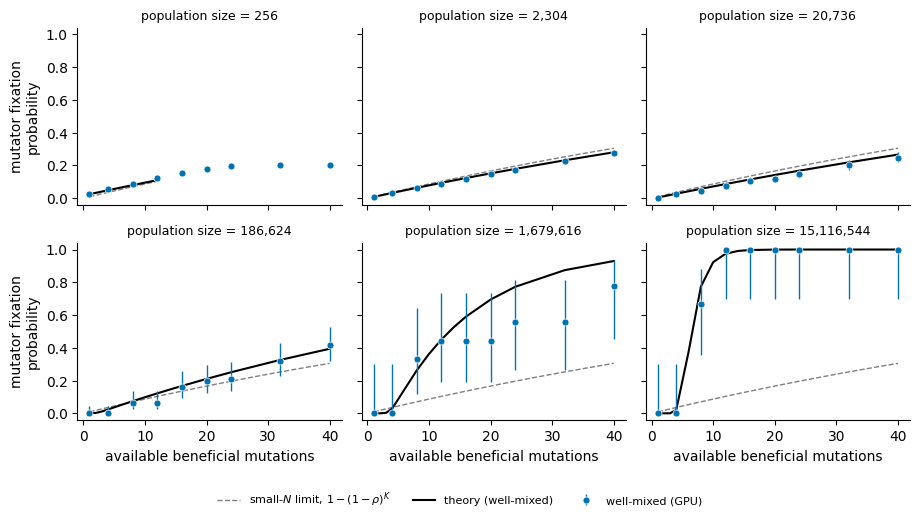

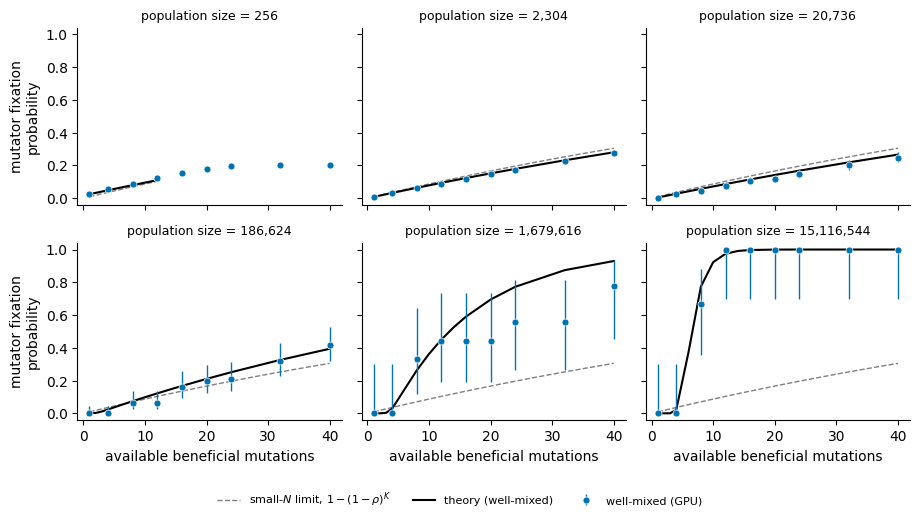

In [11]:
def plot_fixprob(
    df_theory: pd.DataFrame,
    df_points: pd.DataFrame,
    Ns: list,
    treatments: list,
    palette: list,
    markers: list,
    col_wrap: int,
    show_closed_form: bool,
) -> plt.Figure:
    n_row = -(-len(Ns) // col_wrap)
    fig, axs = plt.subplots(
        n_row,
        col_wrap,
        figsize=(3.1 * col_wrap, 2.3 * n_row + 0.6),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    for ax, N in zip(axs.flat, Ns):
        theory = df_theory[df_theory["population size"] == N]
        if show_closed_form:
            Ks = np.arange(
                1, theory["available beneficial mutations"].max() + 1
            )
            ax.plot(
                Ks,
                1.0 - (1.0 - rho) ** Ks,
                color="gray",
                lw=1,
                ls="--",
                label=r"small-$N$ limit, $1 - (1 - \rho)^K$",
                zorder=1,
            )
        ax.plot(
            theory["available beneficial mutations"],
            theory["fixation probability"],
            color="black",
            lw=1.5,
            label=theory["treatment"].iloc[0] if len(theory) else None,
            zorder=2,
        )
        for treatment, color, marker in zip(treatments, palette, markers):
            points = df_points[
                (df_points["treatment"] == treatment)
                & (df_points["population size"] == N)
            ]
            if not len(points):
                continue
            ax.errorbar(
                points["available beneficial mutations"],
                points["fixation probability"],
                yerr=[
                    points["fixation probability"] - points["ci lo"],
                    points["ci hi"] - points["fixation probability"],
                ],
                color=color,
                marker=marker,
                ms=5,
                mec="white",
                mew=0.5,
                ls="none",
                elinewidth=1,
                label=treatment,
                zorder=3,
            )
        ax.set_ylim(-0.04, 1.04)
        ax.set_title(f"population size = {N:,}", fontsize=9)
    for ax in axs[-1]:
        ax.set_xlabel("available beneficial mutations")
    for ax in axs[:, 0]:
        ax.set_ylabel("mutator fixation\nprobability")
    for ax in axs.flat[len(Ns) :]:
        ax.set_visible(False)
    handles = {}
    for ax in axs.flat:
        for handle, label in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(label, handle)
    fig.legend(
        handles.values(),
        handles.keys(),
        loc="lower center",
        ncol=min(len(handles), 3),
        frameon=False,
        fontsize=8,
    )
    sns.despine(fig)
    fig.tight_layout(rect=(0, 0.04 + 0.03 * (-(-len(handles) // 3)), 1, 1))
    return fig


palette = sns.color_palette("colorblind")
tp.tee(
    plot_fixprob,
    df_theory=df_theory,
    df_points=df_data,
    Ns=data_Ns,
    treatments=["well-mixed (GPU)"],
    palette=[palette[0]],
    markers=["o"],
    col_wrap=3,
    show_closed_form=True,
    teeplot_outattrs={"what": "wellmixed"},
    teeplot_subdir=teeplot_subdir,
)


## Fixation Probability: Theory vs. Well-mixed Resimulation


teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=resimulated+ext=.pdf
teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=resimulated+ext=.png


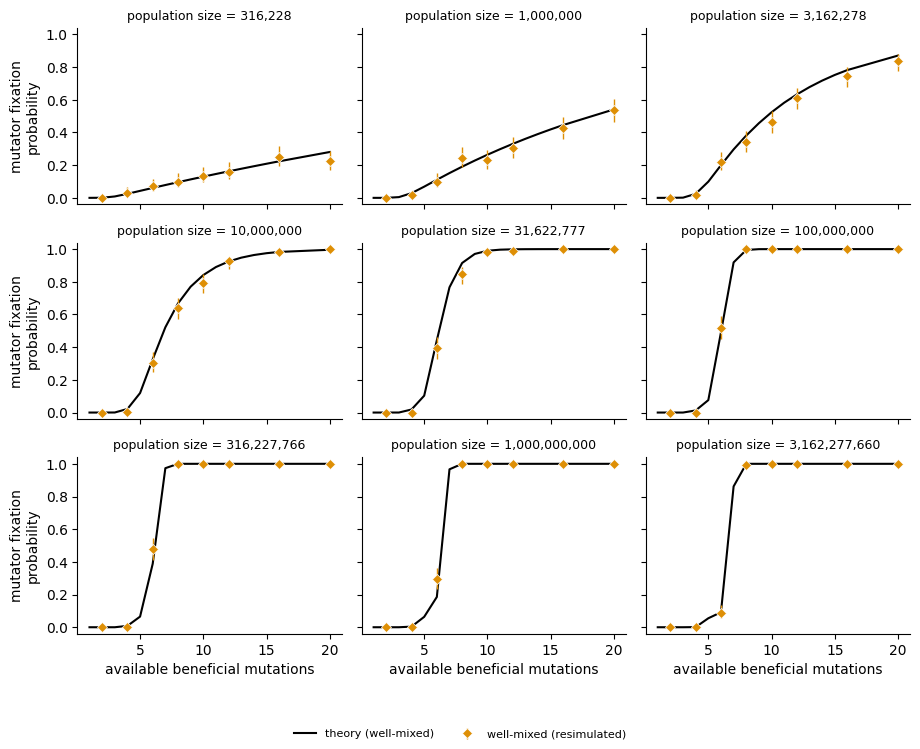

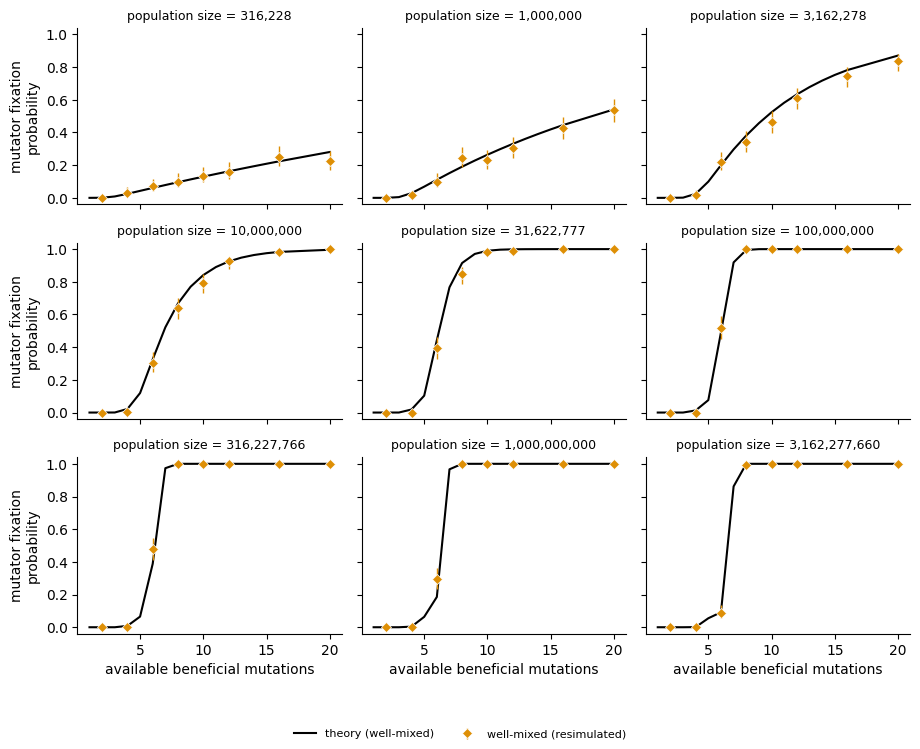

In [12]:
tp.tee(
    plot_fixprob,
    df_theory=df_theory_resim,
    df_points=df_resim,
    Ns=resim_Ns,
    treatments=["well-mixed (resimulated)"],
    palette=[palette[1]],
    markers=["D"],
    col_wrap=3,
    show_closed_form=False,
    teeplot_outattrs={"what": "resimulated"},
    teeplot_subdir=teeplot_subdir,
)


## Extension to 2D Deme Structure

With mutators initially rare, structure matters far more than under 50/50 initialization, where mutators begin everywhere.
A mutator lineage that takes the lead starts in one deme and must spread across the grid as a wave, while distant nonmutators keep adapting.

`calc_denovo_fixprob_demes2d` treats the grid as a nucleation-and-growth process in space and time, in the manner of Kolmogorov-Johnson-Mehl-Avrami kinetics as applied to spreading mutations by Ralph & Coop (2010) and to successive sweeps by Martens & Hallatschek (2011).

1. **Nucleation.** In each deme of $n$ agents, nonmutators establish the next beneficial mutation at rate $n U_b \pi$. Mutators, at frequency $\mu / \delta$, establish a mutation that puts them ahead locally at rate $n (\mu / \delta) U_b' q_0 \pi'$.
2. **Spread.** A clone advances one deme each time a migrant establishes next door, so fronts move at $v = r / \ln(n r)$ demes per generation for growth rate $r$. Because selection is rank-based, being further ahead does not make a front faster.
3. **Nonmutator adaptation.** Successive nonmutator sweeps reach a location as a renewal process.
4. **The race.** A mutator domain adapts $M$ times faster than its surroundings, so it stays ahead until it reaches the fitness peak. Mutators fix if their domains cover the whole grid before nonmutators establish at the peak anywhere still uncovered.

No parameters are fitted.
On small grids one mutator domain can cover everything, and slow nonmutator sweeps give mutators more chances per sweep, so structure helps mutators.
On large grids coverage takes thousands of generations regardless of grid size, so mutators need many more available beneficial mutations than when well-mixed.


In [13]:
records = []
for treatment in "2D, 256/deme (GPU)", "2D, 256/deme (WSE)":
    Ns = sorted(
        df_data.loc[
            df_data["treatment"] == treatment, "population size"
        ].unique()
    )
    for N, K in tqdm([*it.product(Ns, theory_Ks)]):
        if N == 256 and K > 12:
            continue
        records.append(
            {
                "population size": N,
                "available beneficial mutations": K,
                "fixation probability": calc_denovo_fixprob_demes2d(N, K),
                "treatment": "theory (2D demes)",
            },
        )
df_theory_demes2d = pd.DataFrame(records).drop_duplicates(
    ["population size", "available beneficial mutations"],
)
df_theory_demes2d


  0%|          | 0/84 [00:00<?, ?it/s]/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/binder/pylib/theory/_calc_denovo_drift_fixprob.py:17: RuntimeWarning: overflow encountered in scalar negative
  return float(-np.expm1(-N * mu * p_fix * n_gen))
/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/binder/pylib/theory/_calc_denovo_drift_fixprob.py:17: RuntimeWarning: overflow encountered in expm1
  return float(-np.expm1(-N * mu * p_fix * n_gen))
100%|██████████| 112/112 [01:14<00:00,  1.51it/s]


,population size,available beneficial mutations,fixation probability,treatment
0,256,1,-inf,theory (2D demes)
1,256,2,-inf,theory (2D demes)
2,256,3,-inf,theory (2D demes)
3,256,4,-inf,theory (2D demes)
4,256,6,-inf,theory (2D demes)
...,...,...,...,...
179,190848000,16,0.922234,theory (2D demes)
180,190848000,20,0.999982,theory (2D demes)
181,190848000,24,1.000000,theory (2D demes)
182,190848000,32,1.000000,theory (2D demes)


teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=demes2d+ext=.pdf
teeplots/theory-denovo-fixprob/viz=plot-fixprob+what=demes2d+ext=.png


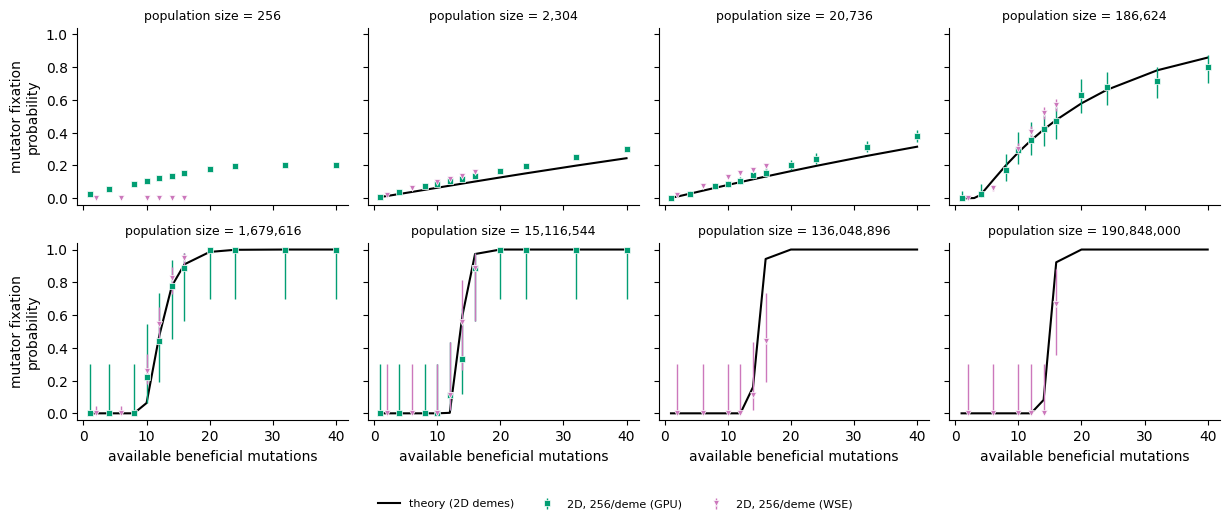

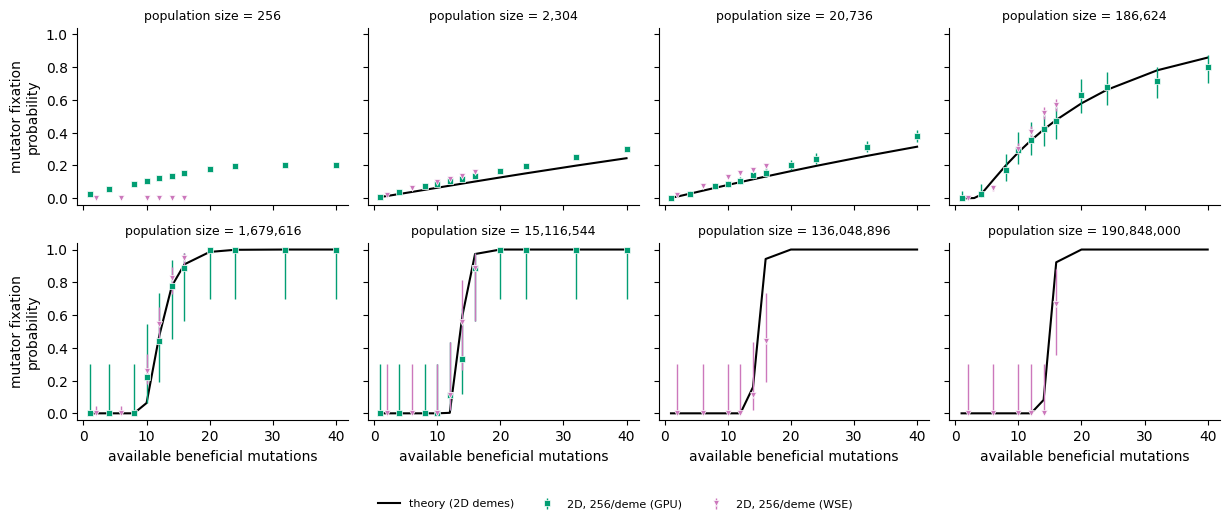

In [14]:
tp.tee(
    plot_fixprob,
    df_theory=df_theory_demes2d,
    df_points=df_data,
    Ns=sorted(df_theory_demes2d["population size"].unique()),
    treatments=["2D, 256/deme (GPU)", "2D, 256/deme (WSE)"],
    palette=[palette[i] for i in (2, 4)],
    markers=["s", "v"],
    col_wrap=4,
    show_closed_form=False,
    teeplot_outattrs={"what": "demes2d"},
    teeplot_subdir=teeplot_subdir,
)


## Critical Adaptive Potential

$K_{50}$ is the adaptive potential at which mutators fix half the time, interpolated linearly between surveyed values of $K$.


In [15]:
def interpolate_k50(group: pd.DataFrame) -> float:
    group = group.sort_values("available beneficial mutations")
    K = group["available beneficial mutations"].to_numpy(dtype=float)
    p = group["fixation probability"].to_numpy()
    (idx,) = np.nonzero((p[:-1] < 0.5) & (p[1:] >= 0.5))
    if not len(idx):
        return np.nan
    i = idx[0]
    return K[i] + (0.5 - p[i]) / (p[i + 1] - p[i]) * (K[i + 1] - K[i])


df_k50 = (
    pd.concat(
        [df_data, df_resim, df_theory, df_theory_resim, df_theory_demes2d],
    )
    .groupby(["treatment", "population size"])
    .apply(interpolate_k50, include_groups=False)
    .rename("K50")
    .dropna()
    .reset_index()
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(
        df_k50.pivot(
            index="population size", columns="treatment", values="K50"
        ),
    )


treatment,"2D, 256/deme (GPU)","2D, 256/deme (WSE)",theory (2D demes),theory (well-mixed),well-mixed (GPU),well-mixed (resimulated)
population size,,,,,,
1.87e+05,16.8,13.6,16.9,NaN,NaN,NaN
1e+06,NaN,NaN,NaN,18.3,NaN,18.7
1.68e+06,12.3,11.7,12.2,13.3,22,NaN
3.16e+06,NaN,NaN,NaN,9.65,NaN,10.5
1e+07,NaN,NaN,NaN,6.89,NaN,7.16
1.51e+07,14.6,13.8,13.7,6.63,7,NaN
3.16e+07,NaN,NaN,NaN,6.18,NaN,6.47
1e+08,NaN,NaN,NaN,6.02,NaN,5.92
1.36e+08,NaN,NaN,14.9,NaN,NaN,NaN


teeplots/theory-denovo-fixprob/viz=plot-k50+ext=.pdf
teeplots/theory-denovo-fixprob/viz=plot-k50+ext=.png


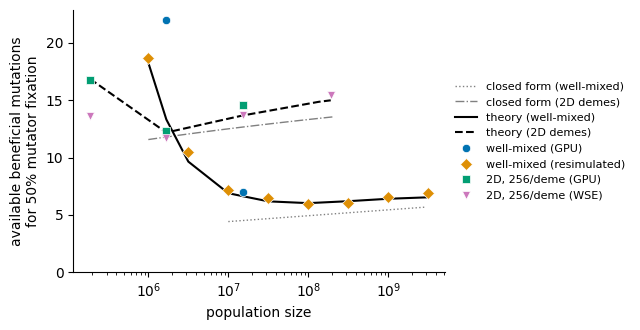

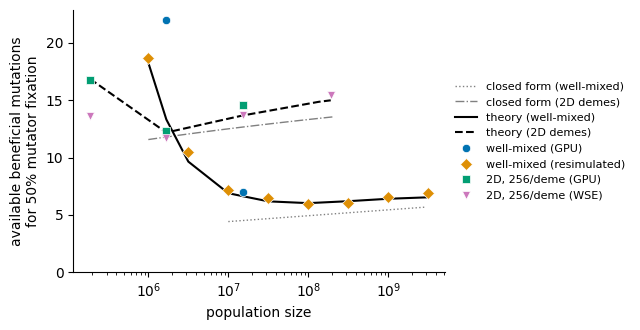

In [16]:
def plot_k50(df_k50: pd.DataFrame, treatments: list) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    palette = sns.color_palette("colorblind")
    colors = [palette[i] for i in (0, 1, 2, 4)]
    markers = ["o", "D", "s", "v"]
    for label, deme_size, Ns in (
        ("closed form (well-mixed)", None, np.geomspace(1e7, 3e9, 20)),
        ("closed form (2D demes)", 256, np.geomspace(1e6, 2e8, 20)),
    ):
        ax.plot(
            Ns,
            [calc_denovo_critical_potential_closed(N, deme_size) for N in Ns],
            color="gray",
            lw=1,
            ls=":" if deme_size is None else "-.",
            label=label,
        )
    for label, ls in ("theory (well-mixed)", "-"), ("theory (2D demes)", "--"):
        theory = df_k50[df_k50["treatment"] == label]
        ax.plot(
            theory["population size"],
            theory["K50"],
            color="black",
            lw=1.5,
            ls=ls,
            label=label,
        )
    for treatment, color, marker in zip(treatments, colors, markers):
        points = df_k50[df_k50["treatment"] == treatment]
        ax.plot(
            points["population size"],
            points["K50"],
            color=color,
            marker=marker,
            ms=6,
            mec="white",
            mew=0.5,
            ls="none",
            label=treatment,
        )
    ax.set_xscale("log")
    ax.set_ylim(0, None)
    ax.set_xlabel("population size")
    ax.set_ylabel("available beneficial mutations\nfor 50% mutator fixation")
    ax.legend(
        frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5)
    )
    sns.despine(fig)
    fig.tight_layout()
    return fig


tp.tee(
    plot_k50,
    df_k50=df_k50,
    treatments=[
        "well-mixed (GPU)",
        "well-mixed (resimulated)",
        "2D, 256/deme (GPU)",
        "2D, 256/deme (WSE)",
    ],
    teeplot_subdir=teeplot_subdir,
)


## Quality Check: Theory vs. Well-mixed Fixation Probabilities


In [17]:
df_check = pd.concat([df_data, df_resim]).merge(
    pd.concat([df_theory, df_theory_resim])
    .drop_duplicates(["population size", "available beneficial mutations"])
    .rename(columns={"fixation probability": "theory fixation probability"})
    .drop(columns="treatment"),
    on=["population size", "available beneficial mutations"],
)
df_check = df_check[df_check["treatment"].str.startswith("well-mixed")]
df_check["error"] = (
    df_check["theory fixation probability"] - df_check["fixation probability"]
)
with pd.option_context("display.max_rows", None):
    display(
        df_check[
            [
                "treatment",
                "population size",
                "available beneficial mutations",
                "num replicates",
                "fixation probability",
                "theory fixation probability",
                "error",
            ]
        ],
    )
df_check.groupby("treatment")["error"].agg(
    ["count", lambda x: np.sqrt(np.mean(x**2)), lambda x: np.abs(x).max()],
)


,treatment,population size,available beneficial mutations,num replicates,fixation probability,theory fixation probability,error
94,well-mixed (GPU),2.560000e+02,1,59049,0.026825,2.456548e-02,-2.259695e-03
95,well-mixed (GPU),2.560000e+02,4,59049,0.054108,4.870050e-02,-5.407101e-03
96,well-mixed (GPU),2.560000e+02,8,59049,0.088537,7.995448e-02,-8.582154e-03
97,well-mixed (GPU),2.560000e+02,12,59049,0.121272,1.101825e-01,-1.108962e-02
98,well-mixed (GPU),2.304000e+03,1,6561,0.007926,7.906946e-03,-1.867516e-05
99,well-mixed (GPU),2.304000e+03,4,6561,0.032769,3.212358e-02,-6.458142e-04
100,well-mixed (GPU),2.304000e+03,8,6561,0.061424,6.350088e-02,2.077317e-03
101,well-mixed (GPU),2.304000e+03,12,6561,0.089773,9.386099e-02,4.088088e-03
102,well-mixed (GPU),2.304000e+03,16,6561,0.118884,1.232369e-01,4.352543e-03
103,well-mixed (GPU),2.304000e+03,20,6561,0.146014,1.516604e-01,5.646076e-03


,count,<lambda_0>,<lambda_1>
treatment,,,
well-mixed (GPU),49,0.076023,0.318283
well-mixed (resimulated),72,0.026618,0.109727
